In [15]:
from scipy.optimize import brentq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# ============================================================
# Actual IDM parameters from SUMO configuration
# ============================================================

IDM = {"v0": 30.0, "a": 1.0, "b": 1.5, "T": 1.5, "s0": 2.0, "delta": 4.0, "l": 5.0}

print("IDM parameters:")
display(pd.DataFrame(IDM.items(), columns=["Parameter", "Value"]))

IDM parameters:


,Parameter,Value
0,v0,30.0
1,a,1.0
2,b,1.5
3,T,1.5
4,s0,2.0
5,delta,4.0
6,l,5.0


In [16]:
def idm_equilibrium_function(v, density, params):
    """
    IDM homogeneous equilibrium equation.

    density: vehicles/km
    v: equilibrium speed (m/s)
    """

    v0 = params["v0"]
    T = params["T"]
    s0 = params["s0"]
    delta = params["delta"]
    l = params["l"]

    # Convert density to vehicles/m
    rho = density / 1000.0

    # Mean net spacing
    s_e = 1.0 / rho - l

    if s_e <= 0:
        raise ValueError("Non-positive net spacing.")

    return (v / v0) ** delta + ((s0 + v * T) / s_e) ** 2 - 1.0


def calculate_equilibrium_speed(density, params):

    v0 = params["v0"]

    s_e = 1000.0 / density - params["l"]

    if s_e <= 0:
        raise ValueError(f"Invalid net spacing at density={density}")

    f_low = idm_equilibrium_function(0.0, density, params)

    f_high = idm_equilibrium_function(v0, density, params)

    # Check whether a root exists in [0, v0]
    if f_low > 0 or f_high < 0:
        return np.nan

    v_e = brentq(idm_equilibrium_function, 0.0, v0, args=(density, params), xtol=1e-12)

    return v_e

### IDM acceleration equation

\begin{equation}
\frac{dv}{dt}
=
a\left[
1-\left(\frac{v}{v_0}\right)^\delta
-\left(\frac{s^*(v,\Delta v)}{s}\right)^2
\right]
\end{equation}

### Desired dynamical distance

\begin{equation}
s^*(v,\Delta v)
=
s_0+vT+\frac{v\Delta v}{2\sqrt{ab}}
\end{equation}

### Homogeneous equilibrium conditions

\begin{equation}
v_i=v_{i-1}=v_e,
\qquad
\Delta v=0,
\qquad
\frac{dv}{dt}=0
\end{equation}

### Equilibrium desired distance

\begin{equation}
s^*(v_e,0)=s_0+v_eT
\end{equation}

### net spacing

\begin{equation}
d=\frac{1}{\rho}=l+s_e
\end{equation}

### IDM homogeneous equilibrium equation

\begin{equation}
\left(\frac{v_e}{v_0}\right)^\delta
+
\left(\frac{s_0+v_eT}{s_e}\right)^2
-1=0
\end{equation}

\begin{equation}
\boxed{
\left(\frac{v_e}{v_0}\right)^\delta
+
\left(
\frac{s_0+v_eT}
{\frac{1000}{\rho}-l}
\right)^2
=1
}
\end{equation}

,density,N,mean_spacing,net_spacing,equilibrium_speed,equilibrium_flow
0,25,30,40.000000,35.000000,19.712891,492.822275
1,30,36,33.333333,28.333333,16.639515,499.185452
2,35,42,28.571429,23.571429,14.003412,490.119412
3,40,48,25.000000,20.000000,11.837405,473.496219
4,55,66,18.181818,13.181818,7.437927,409.085991


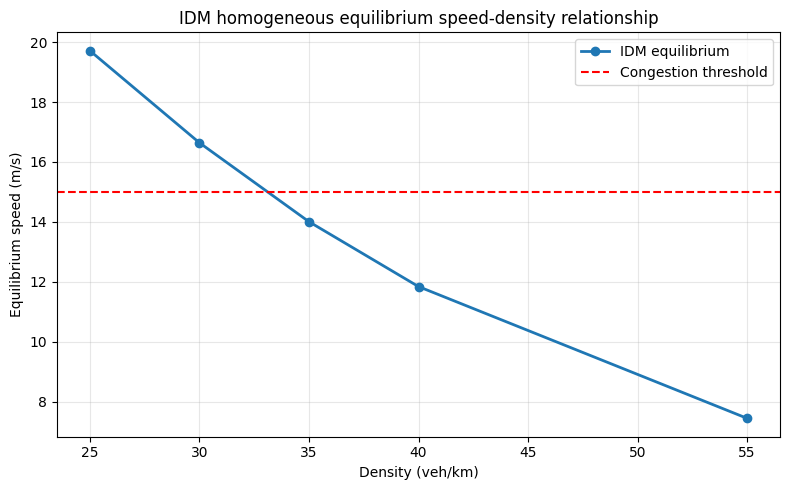

In [17]:
densities = [25, 30, 35, 40, 55]

equilibrium_results = []

for density in densities:
    v_e = calculate_equilibrium_speed(density, IDM)

    equilibrium_results.append(
        {
            "density": density,
            "N": int(density * 1.2),
            "mean_spacing": 1000 / density,
            "net_spacing": 1000 / density - IDM["l"],
            "equilibrium_speed": v_e,
            "equilibrium_flow": density * v_e,
        }
    )

equilibrium_df = pd.DataFrame(equilibrium_results)

display(equilibrium_df)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    equilibrium_df["density"],
    equilibrium_df["equilibrium_speed"],
    "o-",
    linewidth=2,
    label="IDM equilibrium",
)

ax.axhline(15, color="red", linestyle="--", label="Congestion threshold")

ax.set_xlabel("Density (veh/km)")
ax.set_ylabel("Equilibrium speed (m/s)")

ax.set_title("IDM homogeneous equilibrium speed-density relationship")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# Stability analysis


def calculate_idm_derivatives(density, params):
    """
    Calculate IDM partial derivatives at
    homogeneous equilibrium.

    Returns:
        f_v
        f_s
        f_dv
    """

    a = params["a"]
    b = params["b"]

    v0 = params["v0"]
    T = params["T"]
    s0 = params["s0"]

    delta = params["delta"]
    l = params["l"]

    # Equilibrium speed
    v_e = calculate_equilibrium_speed(density, params)

    if not np.isfinite(v_e):
        raise ValueError(f"No equilibrium solution at density={density}")

    # Equilibrium net spacing
    rho = density / 1000.0

    s_e = 1.0 / rho - l

    # Desired gap at equilibrium
    q = s0 + v_e * T

    # --------------------------------------------------------
    # Partial derivative with respect to speed
    # --------------------------------------------------------

    f_v = -a * delta / v0 * (v_e / v0) ** (delta - 1) - 2 * a * q * T / s_e**2

    # --------------------------------------------------------
    # Partial derivative with respect to spacing
    # --------------------------------------------------------

    f_s = 2 * a * q**2 / s_e**3

    # --------------------------------------------------------
    # Partial derivative with respect to relative speed
    # --------------------------------------------------------

    f_dv = -a * q * v_e / (np.sqrt(a * b) * s_e**2)

    return {
        "density": density,
        "v_e": v_e,
        "s_e": s_e,
        "f_v": f_v,
        "f_s": f_s,
        "f_dv": f_dv,
    }


linearisation_results = []

for density in densities:
    result = calculate_idm_derivatives(density, IDM)

    linearisation_results.append(result)

linearisation_df = pd.DataFrame(linearisation_results)

display(linearisation_df)

,density,v_e,s_e,f_v,f_s,f_dv
0,25,19.712891,35.000000,-0.115142,0.046490,-0.414796
1,30,16.639515,28.333333,-0.123498,0.063908,-0.456255
2,35,14.003412,23.571429,-0.137775,0.080820,-0.473414
3,40,11.837405,20.000000,-0.156362,0.097576,-0.477367
4,55,7.437927,13.181818,-0.229188,0.151151,-0.459842


### Nonlinear dynamical system

\begin{equation}
\frac{dv_i}{dt} = 
f(v_i,s_i,\Delta v_i)
=
a\left[
1-\left(\frac{v_i}{v_0}\right)^\delta
-\left(
\frac{s_0+v_iT+
\frac{v_i\Delta v_i}{2\sqrt{ab}}}
{s_i}
\right)^2
\right]
\end{equation}

\begin{equation}
f_v=
\left.\frac{\partial f}{\partial v}
\right|_{(v_e,s_e,0)} = -\frac{a\delta}{v_0}
\left(\frac{v_e}{v_0}\right)^{\delta-1}
-\frac{2aqT}{s_e^2}
\end{equation}

\begin{equation}
f_s=
\left.\frac{\partial f}{\partial s}
\right|_{(v_e,s_e,0)} = =\frac{2aq^2}{s_e^3}
\end{equation}

\begin{equation}
f_{\Delta v}=
\left.\frac{\partial f}{\partial\Delta v}
\right|_{(v_e,s_e,0)} = -\frac{aqv_e}{\sqrt{ab}s_e^2}
\end{equation}

define: 
\begin{equation}
q=s_0+v_eT
\end{equation}

\begin{equation}
\boxed{
\delta\dot v_i
=
(f_v+f_{\Delta v})\delta v_i
-f_{\Delta v}\delta v_{i-1}
+f_s\delta s_i
}
\end{equation}

\begin{equation}
\boxed{
\delta\dot s_i
=
\delta v_{i-1}-\delta v_i
}
\end{equation}

periodic boundary cndition:
\begin{equation}
\delta v_{i+N}=\delta v_i
\end{equation}

fourier wave numbers:
\begin{equation}
\boxed{
k_m=\frac{2\pi m}{N},
\qquad m=0,1,\ldots,N-1
}
\end{equation}

Fourier perturbation ansatz:
\begin{equation}
\boxed{
\delta v_i(t)=V e^{\lambda t}e^{\mathrm{i}ki}
}
\end{equation}

\begin{equation}
\boxed{
\delta s_i(t)=S e^{\lambda t}e^{\mathrm{i}ki}
}
\end{equation}

define phase factor of adjacent vehicles:
\begin{equation}
\boxed{
z=e^{-\mathrm{i}k}
}
\end{equation}

\begin{equation}
\delta v_{i-1}=z\delta v_i
\end{equation}

Thus after flourier decomposition:
\begin{equation}
\begin{cases}
\lambda V=
[f_v+f_{\Delta v}(1-z)]V+f_sS
\\[6pt]
\lambda S=(z-1)V
\end{cases}
\end{equation}

\begin{equation}
\begin{pmatrix}
\lambda-f_v-f_{\Delta v}(1-z)&-f_s\\
1-z&\lambda
\end{pmatrix}
\begin{pmatrix}
V\\
S
\end{pmatrix}
=
\begin{pmatrix}
0\\
0
\end{pmatrix}
\end{equation}

Characteristic equation:
\begin{equation}
\boxed{
\lambda^2+B\lambda+C=0
}
\end{equation}
where
\begin{equation}
\boxed{
B=-[f_v+f_{\Delta v}(1-z)]
}
\end{equation}

\begin{equation}
\boxed{
C=f_s(1-z)
}
\end{equation}

Eigenvalues:

\begin{equation}
\boxed{
\lambda_{\pm}
=
\frac{-B\pm\sqrt{B^2-4C}}{2}
}
\end{equation}

stability criterion:
\begin{equation}
\lambda=\sigma+\mathrm{i}\omega
\end{equation}

\begin{equation}
\boxed{
\sigma_{\max}(\rho)
=
\max_{\substack{m=1,\ldots,N-1\\j=\pm}}
\operatorname{Re}[\lambda_{m,j}(\rho)]
}
\end{equation}

\begin{equation}
\boxed{
\begin{cases}
\sigma_{\max}<0,
&\text{Linearly stable}
\\
\sigma_{\max}>0,
&\text{Linearly unstable}
\\
\sigma_{\max}=0,
&\text{Marginal stability}
\end{cases}
}
\end{equation}

这里：
- \(f_v\)：车辆对自身速度变化的响应。
- \(f_s\)：车辆对间距变化的响应。
- \(f_{\Delta v}\)：车辆对相对速度变化的响应。

In [19]:
# How disturbances spread among vehicles.

RING_LENGTH = 1200


def calculate_idm_eigenvalues(density, n_vehicles, params):
    """
    Calculate eigenvalues of linearised IDM
    for all non-zero Fourier modes of a finite ring.
    """

    derivatives = calculate_idm_derivatives(density, params)

    f_v = derivatives["f_v"]
    f_s = derivatives["f_s"]
    f_dv = derivatives["f_dv"]

    # Allowed Fourier modes for periodic ring
    modes = np.arange(1, n_vehicles)

    k_values = 2 * np.pi * modes / n_vehicles

    rows = []

    for m, k in zip(modes, k_values):
        z = np.exp(-1j * k)

        # Characteristic equation:
        # lambda^2 + B*lambda + C = 0

        B = -(f_v + f_dv * (1 - z))

        C = -f_s * (z - 1)

        eigenvalues = np.roots([1.0, B, C])

        for j, lam in enumerate(eigenvalues):
            rows.append(
                {
                    "density": density,
                    "N": n_vehicles,
                    "mode": m,
                    "k": k,
                    "eigenvalue": j,
                    "real": lam.real,
                    "imag": lam.imag,
                    "growth_rate": lam.real,
                    "oscillation_frequency": (abs(lam.imag)),
                }
            )

    return pd.DataFrame(rows)


# ============================================================
# Linear stability analysis across densities
# ============================================================

stability_results = []

for density in densities:
    n = int(density * RING_LENGTH / 1000)

    eig_df = calculate_idm_eigenvalues(density, n, IDM)

    stability_results.append(eig_df)

eigenvalue_df = pd.concat(stability_results, ignore_index=True)

display(eigenvalue_df.head())


# The maximum growth rate of each density


stability_summary = (
    eigenvalue_df.groupby("density")
    .agg(
        max_growth_rate=("growth_rate", "max"),
        max_oscillation_frequency=("oscillation_frequency", "max"),
    )
    .reset_index()
)

stability_summary["stability"] = np.where(
    stability_summary["max_growth_rate"] < -1e-10,
    "Stable",
    np.where(stability_summary["max_growth_rate"] > 1e-10, "Unstable", "Marginal"),
)

display(stability_summary)

,density,N,mode,k,eigenvalue,real,imag,growth_rate,oscillation_frequency
0,25,30,1,0.209440,0,-0.114073,-0.001655,-0.114073,0.001655
1,25,30,1,0.209440,1,-0.010133,-0.084586,-0.010133,0.084586
2,25,30,2,0.418879,0,-0.038163,-0.166993,-0.038163,0.166993
3,25,30,2,0.418879,1,-0.112840,-0.001719,-0.112840,0.001719
4,25,30,3,0.628319,0,-0.082110,-0.242416,-0.082110,0.242416


,density,max_growth_rate,max_oscillation_frequency,stability
0,25,-0.010133,0.412039,Stable
1,30,-0.002422,0.459815,Stable
2,35,0.001173,0.481601,Unstable
3,40,0.002383,0.494015,Unstable
4,55,0.003846,0.521971,Unstable


这张图的解释：
- 曲线低于零：均匀交通流线性稳定。
- 曲线高于零：均匀交通流线性不稳定。
- 曲线穿过零：有限系统的线性稳定性边界。

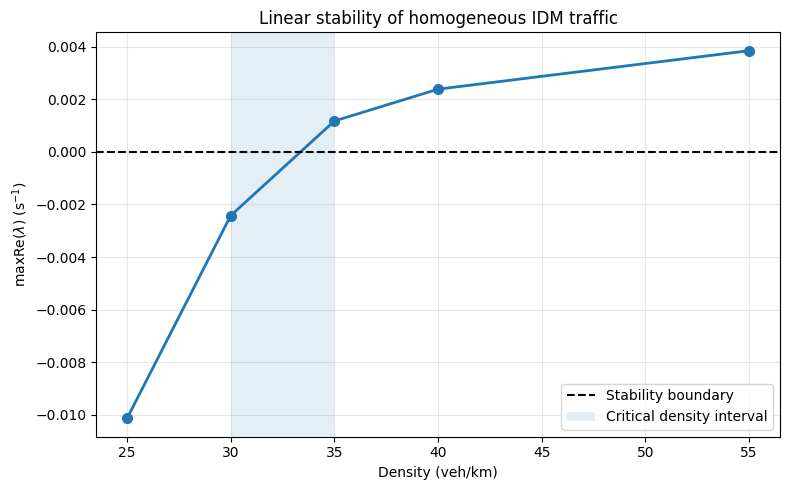

In [ ]:
# # Theoretical stability curve

# N_values = np.arange(18, 73)

# bifurcation_results = []

# for N in N_values:
#     # Calculate the corresponding density
#     density = N * 1000.0 / RING_LENGTH

#     # Homogeneous equilibrium speed
#     v_e = calculate_equilibrium_speed(density, IDM)

#     # Calculate eigenvalues of all non-zero Fourier modes
#     eig_df = calculate_idm_eigenvalues(density, N, IDM)

#     # Maximum growth rate
#     max_growth = eig_df["growth_rate"].max()

#     bifurcation_results.append(
#         {
#             "N": N,
#             "density": density,
#             "equilibrium_speed": v_e,
#             "max_growth_rate": max_growth,
#             "stability": (
#                 "Stable"
#                 if max_growth < -1e-10
#                 else "Unstable"
#                 if max_growth > 1e-10
#                 else "Marginal"
#             ),
#         }
#     )

# bifurcation_df = pd.DataFrame(bifurcation_results)

# # ============================================================
# # Plot equilibrium branches
# # ============================================================

# stable = bifurcation_df["max_growth_rate"] < -1e-10

# unstable = bifurcation_df["max_growth_rate"] > 1e-10


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    stability_summary["density"],
    stability_summary["max_growth_rate"],
    "o-",
    linewidth=2,
    markersize=7,
)

# # Stable equilibrium branch
# ax.plot(stability_summary["density"], stability_summary["max_growth_rate"].where(stable), color="blue", linewidth=2.5, label="Stable equilibrium")

# # Unstable equilibrium branch
# ax.plot(
#     stability_summary["density"],
#     stability_summary["max_growth_rate"].where(unstable),
#     color="red",
#     linestyle="--",
#     linewidth=2.5,
#     label="Unstable equilibrium",
# )

ax.axhline(0, color="black", linestyle="--", label="Stability boundary")

ax.axvspan(30, 35, alpha=0.12, label="Critical density interval")

ax.set_xlabel("Density (veh/km)")

ax.set_ylabel(r"$\max \operatorname{Re}(\lambda)$ (s$^{-1}$)")

ax.set_title("Linear stability of homogeneous IDM traffic")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

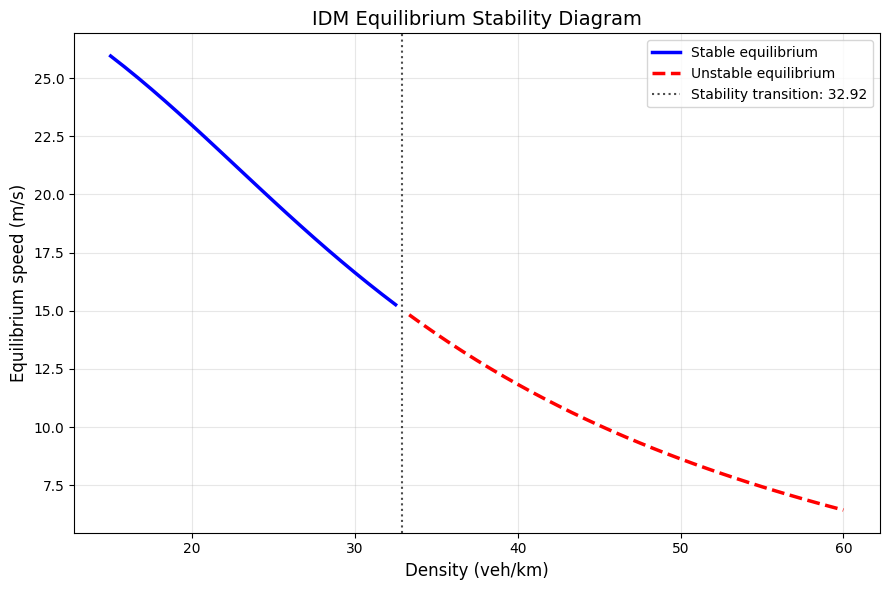

In [21]:
# ============================================================
# IDM equilibrium stability diagram
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sweep over different vehicle numbers
N_values = np.arange(18, 73)

bifurcation_results = []

for N in N_values:
    # Calculate the corresponding density
    density = N * 1000.0 / RING_LENGTH

    # Homogeneous equilibrium speed
    v_e = calculate_equilibrium_speed(density, IDM)

    # Calculate eigenvalues of all non-zero Fourier modes
    eig_df = calculate_idm_eigenvalues(density, N, IDM)

    # Maximum growth rate
    max_growth = eig_df["growth_rate"].max()

    bifurcation_results.append(
        {
            "N": N,
            "density": density,
            "equilibrium_speed": v_e,
            "max_growth_rate": max_growth,
            "stability": (
                "Stable"
                if max_growth < -1e-10
                else "Unstable"
                if max_growth > 1e-10
                else "Marginal"
            ),
        }
    )

bifurcation_df = pd.DataFrame(bifurcation_results)

# ============================================================
# Plot equilibrium branches
# ============================================================

stable = bifurcation_df["max_growth_rate"] < -1e-10

unstable = bifurcation_df["max_growth_rate"] > 1e-10

rho = bifurcation_df["density"]

v_e = bifurcation_df["equilibrium_speed"]

fig, ax = plt.subplots(figsize=(9, 6))

# Stable equilibrium branch
ax.plot(rho, v_e.where(stable), color="blue", linewidth=2.5, label="Stable equilibrium")

# Unstable equilibrium branch
ax.plot(
    rho,
    v_e.where(unstable),
    color="red",
    linestyle="--",
    linewidth=2.5,
    label="Unstable equilibrium",
)

# Approximate stability transition
transition_indices = np.where(np.diff(unstable.astype(int)) == 1)[0]

if len(transition_indices) > 0:
    idx = transition_indices[0]

    rho_critical = (rho.iloc[idx] + rho.iloc[idx + 1]) / 2

    ax.axvline(
        rho_critical,
        color="black",
        linestyle=":",
        alpha=0.7,
        label=f"Stability transition: {rho_critical:.2f}",
    )

ax.set_xlabel("Density (veh/km)", fontsize=12)

ax.set_ylabel("Equilibrium speed (m/s)", fontsize=12)

ax.set_title("IDM Equilibrium Stability Diagram", fontsize=14)

ax.legend()

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()


,density,N,max_growth_rate
0,25.00,30,-0.010133
1,25.25,30,-0.009819
2,25.50,31,-0.008907
3,25.75,31,-0.008605
4,26.00,31,-0.008302
...,...,...,...
76,44.00,53,0.002505
77,44.25,53,0.002515
78,44.50,53,0.002553
79,44.75,54,0.002730


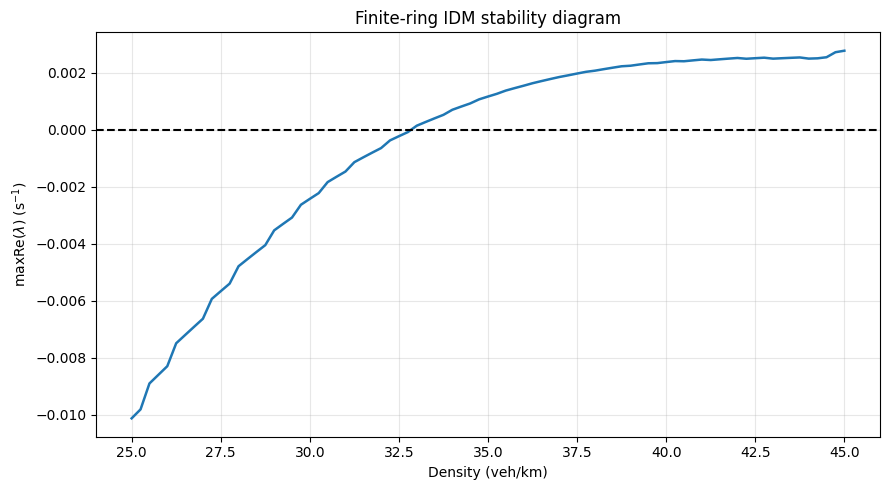

In [22]:
# ============================================================
# Fine density sweep: finite-ring stability
# ============================================================

density_scan = np.arange(25, 45.25, 0.25)

scan_results = []

for density in density_scan:
    n = int(round(density * RING_LENGTH / 1000))

    eig_df = calculate_idm_eigenvalues(density, n, IDM)

    max_growth = eig_df["growth_rate"].max()

    scan_results.append({"density": density, "N": n, "max_growth_rate": max_growth})

scan_df = pd.DataFrame(scan_results)

display(scan_df)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(scan_df["density"], scan_df["max_growth_rate"], linewidth=1.8)

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Density (veh/km)")
ax.set_ylabel(r"$\max \operatorname{Re}(\lambda)$ (s$^{-1}$)")

ax.set_title("Finite-ring IDM stability diagram")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path
from collections import Counter
import re
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

# ============================================================
# Project paths
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "configs").exists()
    and (PROJECT_ROOT / "scripts").exists()
    and (PROJECT_ROOT / "data").exists()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Cannot find project root.")

    PROJECT_ROOT = PROJECT_ROOT.parent


FCD_DIR = PROJECT_ROOT / "data" / "raw" / "SUMO_ring_idm"

OUTPUT_DIR = PROJECT_ROOT / "analysis" / "outputs" / "cluster_distribution"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# # ============================================================
# # Simulation parameters
# # ============================================================

# RING_LENGTH = 1200.0

# FREE_SPEED = 30.0
# JAM_RATIO = 0.5

# # Congestion criterion:
# # v / v_free < 0.5
# JAM_SPEED = FREE_SPEED * JAM_RATIO

# # Initial warm-up setting
# WARMUP = 100.0

# # Network edge offsets
# # Must be verified against ring_1200.net.xml
# EDGE_OFFSETS = {
#     "e0": 0.0,
#     "e1": 300.0,
#     "e2": 600.0,
#     "e3": 900.0,
# }

# print("Project root:", PROJECT_ROOT)
# print("FCD directory:", FCD_DIR)
# print("Output directory:", OUTPUT_DIR)
# print("Congestion threshold:", JAM_SPEED, "m/s")
# print("Warm-up:", WARMUP, "s")

# ============================================================
# Experiment settings
# ============================================================

SEED = 501

DENSITY_RUNS = {
    30: 36,
    35: 42,
    40: 48,
    55: 66,
}

# Use the same time interval as the space-time diagrams
TIME_START = 600.0
TIME_END = 1800.0

FCD_FILES = {}

for density, n in DENSITY_RUNS.items():
    filename = f"fcd_idm_L1200_n{n}_s{SEED}.xml"

    fcd_file = FCD_DIR / filename

    if not fcd_file.exists():
        raise FileNotFoundError(f"FCD file not found: {fcd_file}")

    FCD_FILES[density] = fcd_file

    print(f"Density={density}, N={n}, Seed={SEED}: {filename}")

# ============================================================
# Load FCD data
# ============================================================


def load_fcd_data(
    fcd_file, ring_length=RING_LENGTH, time_start=TIME_START, time_end=TIME_END
):
    """
    Read SUMO FCD XML.

    Convert local edge positions into global ring positions.

    Returns:
        DataFrame with:
        time, vehicle_id, position, speed
    """

    edge_length = ring_length / 4

    edge_offsets = {
        "e0": 0.0,
        "e1": edge_length,
        "e2": 2 * edge_length,
        "e3": 3 * edge_length,
    }

    records = []

    for event, element in ET.iterparse(fcd_file, events=("end",)):
        if element.tag != "timestep":
            continue

        t = float(element.get("time"))

        if t < time_start:
            element.clear()
            continue

        if t >= time_end:
            break

        for vehicle in element.findall("vehicle"):
            vehicle_id = vehicle.get("id")

            lane_id = vehicle.get("lane")

            local_pos = float(vehicle.get("pos"))

            speed = float(vehicle.get("speed"))

            edge_id = lane_id.rsplit("_", 1)[0]

            if edge_id not in edge_offsets:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            global_pos = (edge_offsets[edge_id] + local_pos) % ring_length

            records.append(
                {
                    "time": t,
                    "vehicle_id": vehicle_id,
                    "position": global_pos,
                    "speed": speed,
                }
            )

        element.clear()

    if not records:
        raise ValueError(f"No observations found in {fcd_file}")

    df = pd.DataFrame(records)

    return df


# ============================================================
# Load all density experiments
# ============================================================

speed_data = {}

for density, fcd_file in FCD_FILES.items():
    print(f"\nLoading density = {density} veh/km")

    df = load_fcd_data(
        fcd_file=fcd_file,
        ring_length=RING_LENGTH,
        time_start=TIME_START,
        time_end=TIME_END,
    )

    speed_data[density] = df

    print(
        f"Observations: {len(df):,}\n"
        f"Vehicles: {df['vehicle_id'].nunique()}\n"
        f"Time steps: {df['time'].nunique()}"
    )

print("\nAll experiments loaded.")

Density=30, N=36, Seed=501: fcd_idm_L1200_n36_s501.xml
Density=35, N=42, Seed=501: fcd_idm_L1200_n42_s501.xml
Density=40, N=48, Seed=501: fcd_idm_L1200_n48_s501.xml
Density=55, N=66, Seed=501: fcd_idm_L1200_n66_s501.xml

Loading density = 30 veh/km
Observations: 43,200
Vehicles: 36
Time steps: 1200

Loading density = 35 veh/km
Observations: 50,400
Vehicles: 42
Time steps: 1200

Loading density = 40 veh/km
Observations: 57,600
Vehicles: 48
Time steps: 1200

Loading density = 55 veh/km
Observations: 79,200
Vehicles: 66
Time steps: 1200

All experiments loaded.


,density,mean_speed
0,30,16.495343
1,35,13.017590
2,40,10.779873
3,55,6.872601


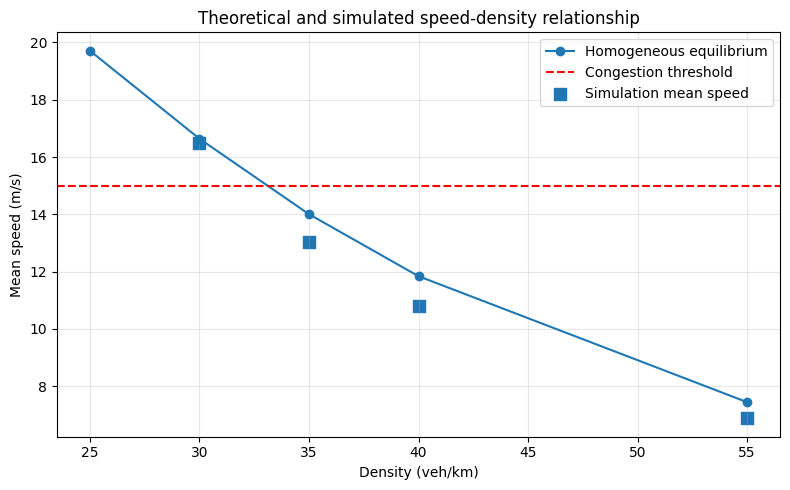

In [24]:
# Theoretical equilibrium speed
theoretical_speed = equilibrium_df[["density", "equilibrium_speed"]].copy()

# Empirical mean speed from FCD
empirical_speed_rows = []

for density, df in speed_data.items():
    empirical_speed_rows.append(
        {"density": density, "mean_speed": df.groupby("time")["speed"].mean().mean()}
    )

empirical_speed = pd.DataFrame(empirical_speed_rows)

display(empirical_speed)
# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    theoretical_speed["density"],
    theoretical_speed["equilibrium_speed"],
    "o-",
    label="Homogeneous equilibrium",
)

ax.axhline(15, color="red", linestyle="--", label="Congestion threshold")

ax.scatter(
    empirical_speed["density"],
    empirical_speed["mean_speed"],
    marker="s",
    s=70,
    label="Simulation mean speed",
)

ax.set_xlabel("Density (veh/km)")
ax.set_ylabel("Mean speed (m/s)")

ax.set_title("Theoretical and simulated speed-density relationship")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,a,max_growth_rate
0,0.300000,0.016045
1,0.324832,0.015637
2,0.349664,0.015171
3,0.374497,0.014655
4,0.399329,0.014094
...,...,...
145,3.900671,-0.015180
146,3.925503,-0.015197
147,3.950336,-0.015213
148,3.975168,-0.015229


Zero-crossing intervals:
[(1.04496644295302, 1.0697986577181209)]
Critical acceleration = 1.0667145190 m/s^2
Growth rate at root = -1.040e-16


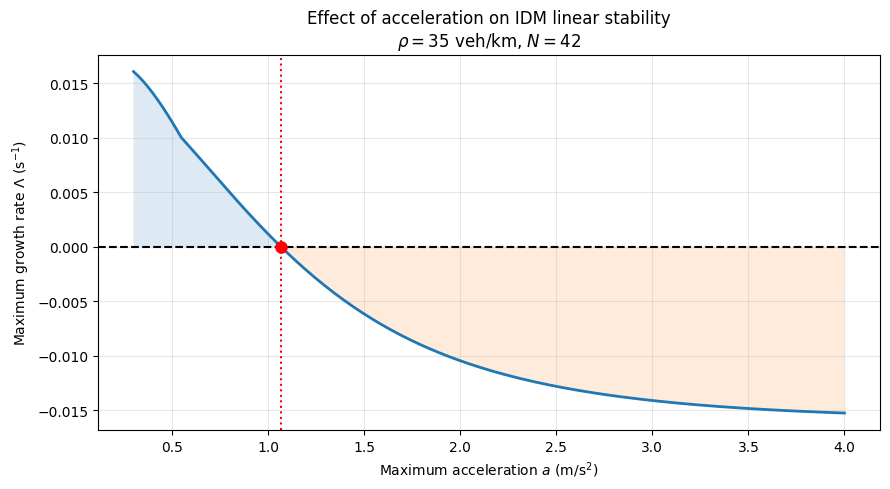

In [25]:
# ============================================================
# Effect of maximum acceleration on IDM stability
# ============================================================


def calculate_max_growth_rate(a_value, density, n_vehicles, params):

    params_test = params.copy()

    params_test["a"] = float(a_value)

    eig_df = calculate_idm_eigenvalues(
        density=density, n_vehicles=n_vehicles, params=params_test
    )

    return eig_df["real"].max()


density = 35
n_vehicles = 42

a_values = np.linspace(0.3, 4.0, 150)

rows = []

for a_value in a_values:
    growth = calculate_max_growth_rate(
        a_value=a_value, density=density, n_vehicles=n_vehicles, params=IDM
    )

    rows.append({"a": a_value, "max_growth_rate": growth})

acceleration_stability = pd.DataFrame(rows)

display(acceleration_stability)

# ============================================================
# Find intervals containing zero crossings
# ============================================================

a_scan = acceleration_stability["a"].to_numpy()

growth_scan = acceleration_stability["max_growth_rate"].to_numpy()

crossing_intervals = []

for i in range(len(a_scan) - 1):
    if growth_scan[i] * growth_scan[i + 1] < 0:
        crossing_intervals.append((a_scan[i], a_scan[i + 1]))

print("Zero-crossing intervals:")
print(crossing_intervals)

# ============================================================
# Refine critical acceleration
# ============================================================

critical_accelerations = []

for a_left, a_right in crossing_intervals:
    a_critical = brentq(
        calculate_max_growth_rate,
        a_left,
        a_right,
        args=(density, n_vehicles, IDM),
        xtol=1e-10,
    )

    critical_accelerations.append(a_critical)

    print(f"Critical acceleration = {a_critical:.10f} m/s^2")

    print(
        f"Growth rate at root = "
        f"{calculate_max_growth_rate(a_critical, density, n_vehicles, IDM):.3e}"
    )

# ============================================================
# Effect of maximum acceleration on IDM stability
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    acceleration_stability["a"],
    acceleration_stability["max_growth_rate"],
    linewidth=2,
    label=r"$\Lambda(a)$",
)

ax.axhline(0, color="black", linestyle="--", label="Stability boundary")

# ------------------------------------------------------------
# Mark critical acceleration
# ------------------------------------------------------------

for i, a_c in enumerate(critical_accelerations):
    ax.axvline(
        a_c,
        color="red",
        linestyle=":",
        linewidth=1.5,
        label=(rf"$a_c={a_c:.6f}\ \mathrm{{m/s^2}}$"),
    )

    ax.scatter(a_c, 0, color="red", s=65, zorder=5)

# ------------------------------------------------------------
# Stable / unstable regions
# ------------------------------------------------------------

ax.fill_between(
    acceleration_stability["a"],
    acceleration_stability["max_growth_rate"],
    0,
    where=(acceleration_stability["max_growth_rate"] > 0),
    alpha=0.15,
    label="Unstable",
)

ax.fill_between(
    acceleration_stability["a"],
    acceleration_stability["max_growth_rate"],
    0,
    where=(acceleration_stability["max_growth_rate"] < 0),
    alpha=0.15,
    label="Stable",
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(r"Maximum acceleration $a$ (m/s$^2$)")

ax.set_ylabel(r"Maximum growth rate $\Lambda$ (s$^{-1}$)")

ax.set_title(
    "Effect of acceleration on IDM linear stability\n"
    + rf"$\rho={density}$ veh/km, $N={n_vehicles}$"
)


ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Increasing the maximum acceleration stabilises homogeneous traffic by suppressing the amplification of velocity perturbations.

### Effect of Maximum Acceleration on Traffic Stability

Increasing the maximum acceleration parameter \(a\) modifies the response of vehicles to changes in speed and spacing. In the Intelligent Driver Model, this changes the linear stability of homogeneous traffic flow.

When the maximum real part of the linearised eigenvalues becomes negative, small perturbations decay rather than amplify. Consequently, stop-and-go oscillations may dissipate, allowing the system to approach a homogeneous traffic state.

Importantly, the disappearance of stop-and-go waves does not necessarily imply a return to free-flow conditions. At sufficiently high densities, homogeneous traffic may remain uniformly slow, even though it is dynamically stable.

In [26]:
a_values = [0.5, 1.0, 1.5, 2.0, 3.0]

density = 35

rows = []

for a in a_values:
    params = IDM.copy()
    params["a"] = a

    v_e = calculate_equilibrium_speed(density, params)

    eig_df = calculate_idm_eigenvalues(density, n_vehicles=48, params=params)

    rows.append(
        {"a": a, "equilibrium_speed": v_e, "max_growth_rate": eig_df["real"].max()}
    )

comparison = pd.DataFrame(rows)

display(comparison)

,a,equilibrium_speed,max_growth_rate
0,0.5,14.003412,0.012432
1,1.0,14.003412,0.001256
2,1.5,14.003412,-0.004712
3,2.0,14.003412,-0.008012
4,3.0,14.003412,-0.010770
